# 1. Problem Statement

* The objective of this project is to analyze residential housing data from Ames, Iowa and predict the final sale price (SalePrice) of each house based on 79 explanatory variables covering location, size, quality, and condition.
* The project also aims to determine the relationship between key house features and price, compare multiple regression models, and provide suggestions for buyers based on area, price, and requirements.

# 2. Import Libraries

* The required Python libraries are imported for data analysis, visualization, and machine learning.

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Load Dataset

* The house price dataset is loaded using Pandas for further analysis.

In [44]:
df = pd.read_csv('data.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# 4. Data Understanding

In [45]:
df.shape

(1460, 81)

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [47]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [48]:
# Numeric vs categorical column count
numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(include=['object']).columns
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numeric columns: 38
Categorical columns: 43


# 5. Data Cleaning

In [49]:
# Missing values check
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100
pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})

,Missing Count,Missing %
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [50]:
# Columns where NA actually means "feature not present" (per data dictionary)
none_fill_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
                   'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                   'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
                   'MasVnrType']
df[none_fill_cols] = df[none_fill_cols].fillna('None')

In [51]:
# Numeric columns where NA means 0 (feature absent)
zero_fill_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
                   'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
                   'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
df[zero_fill_cols] = df[zero_fill_cols].fillna(0)

In [52]:
# LotFrontage - fill with median grouped by Neighborhood (location-based estimate)
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

In [53]:
# Electrical - only 1 missing, fill with mode
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

In [54]:
# Confirm no missing values left
df.isnull().sum().sum()

np.int64(0)

In [55]:
# Duplicates check
df.duplicated().sum()

np.int64(0)

In [56]:
# Data type correction - MSSubClass is a categorical code, not a number
df['MSSubClass'] = df['MSSubClass'].astype(str)

# 6. Exploratory Data Analysis
### 1. Distribution of SalePrice

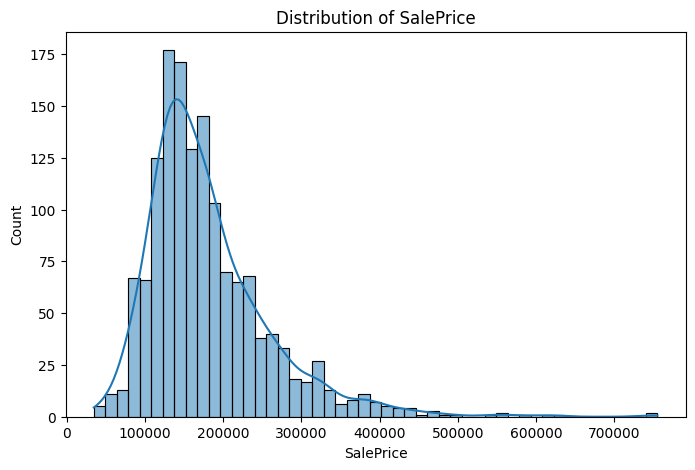

Skewness: 1.8828757597682129


In [57]:
plt.figure(figsize=(8,5))
sns.histplot(df['SalePrice'], kde=True)
plt.title('Distribution of SalePrice')
plt.show()

print("Skewness:", df['SalePrice'].skew())

### 2. SalePrice by Overall Quality

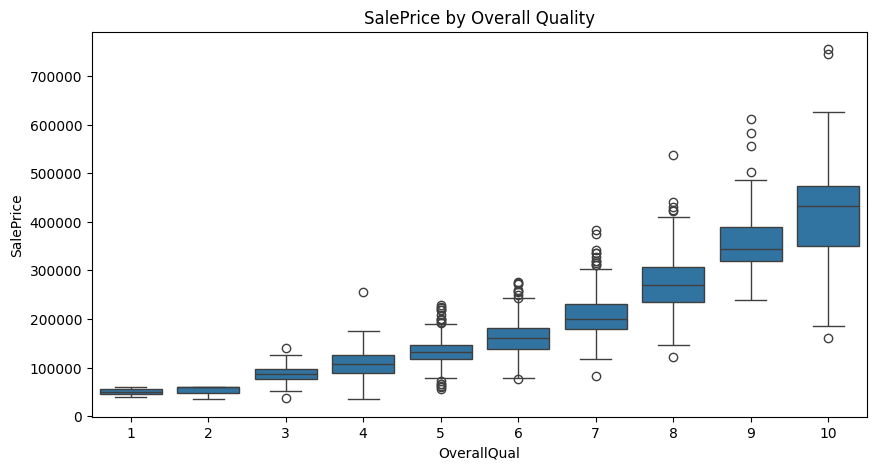

In [58]:
plt.figure(figsize=(10,5))
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.title('SalePrice by Overall Quality')
plt.show()

### 3. SalePrice by Neighborhood

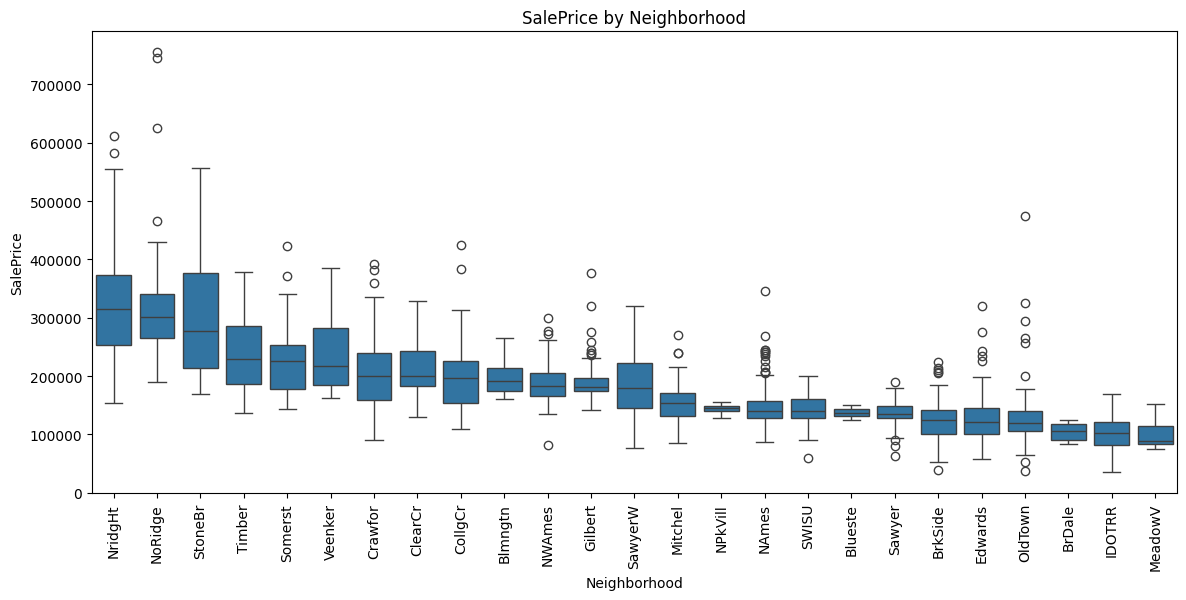

In [59]:
plt.figure(figsize=(14,6))
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
sns.boxplot(x='Neighborhood', y='SalePrice', data=df, order=order)
plt.xticks(rotation=90)
plt.title('SalePrice by Neighborhood')
plt.show()

### 4. Living Area vs SalePrice

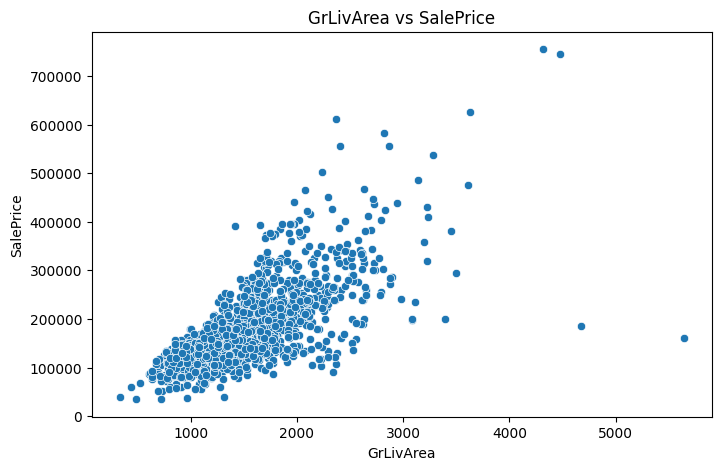

In [60]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)
plt.title('GrLivArea vs SalePrice')
plt.show()

### 5. Year Built vs SalePrice

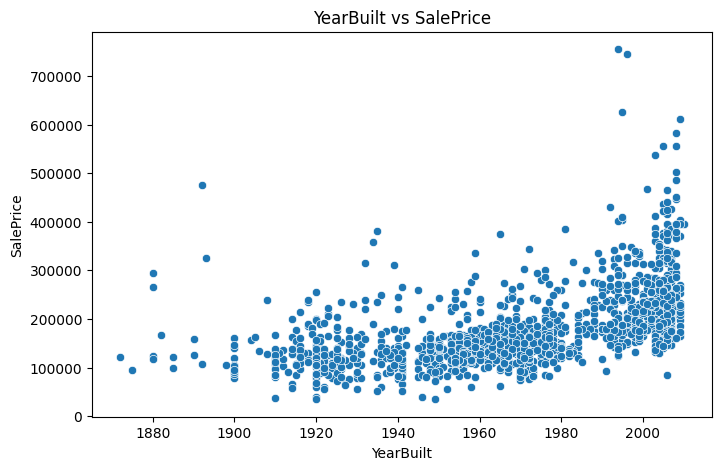

In [61]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)
plt.title('YearBuilt vs SalePrice')
plt.show()

### 6. Basement Area vs SalePrice

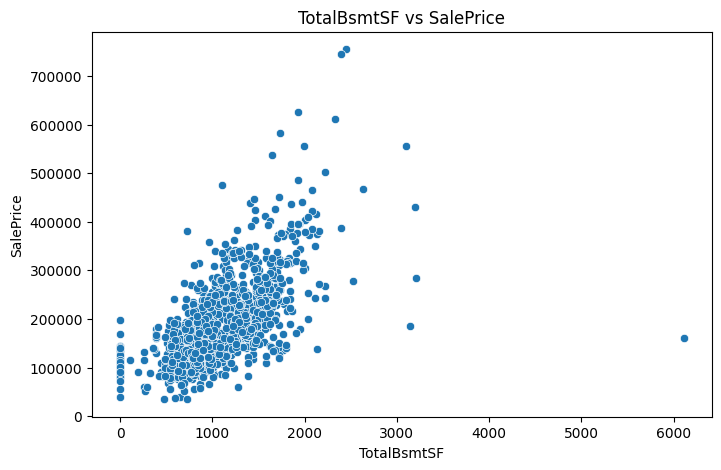

In [62]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)
plt.title('TotalBsmtSF vs SalePrice')
plt.show()

### EDA Findings

* SalePrice is right-skewed, indicating a log transformation will be needed before modeling.
* OverallQual shows a strong, near-linear relationship with SalePrice — higher quality homes command significantly higher prices.
* Neighborhood has a large effect on price, with some neighborhoods (e.g. NoRidge, NridgHt, StoneBr) commanding much higher median prices than others.
* GrLivArea and TotalBsmtSF both show positive linear relationships with SalePrice, with a few outliers (large area but low price).
* Newer YearBuilt homes generally sell for more, though the relationship is noisier than OverallQual or GrLivArea.

### 7. Correlation Heatmap

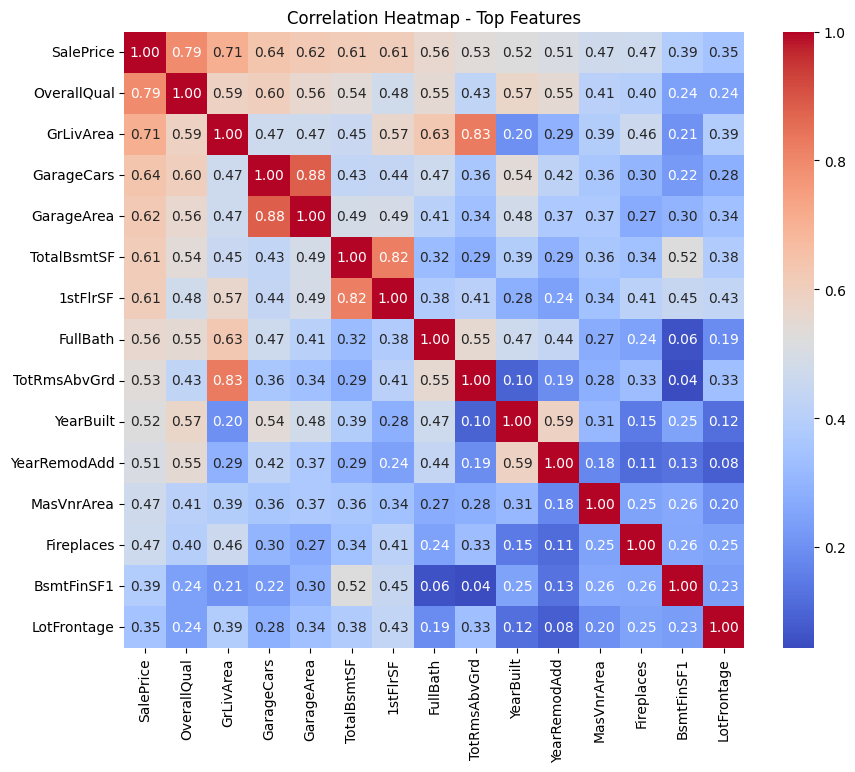

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


In [63]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
top_features = corr['SalePrice'].sort_values(ascending=False).head(15).index

plt.figure(figsize=(10,8))
sns.heatmap(numeric_df[top_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap - Top Features')
plt.show()

corr['SalePrice'].sort_values(ascending=False).head(15)

### Correlation Findings

* OverallQual, GrLivArea, GarageCars, GarageArea, and TotalBsmtSF show the strongest positive correlation with SalePrice.
* GarageCars and GarageArea are highly correlated with each other (multicollinearity), as are TotalBsmtSF and 1stFlrSF.
* These correlated pairs will be considered during feature engineering to avoid redundancy in linear models.

In [64]:
df_original = df.copy()

# 7. Feature Engineering

In [65]:
# New derived features
df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
df['HouseAge'] = df['YrSold'] - df['YearBuilt']
df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
df['TotalBath'] = (df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath'])

In [66]:
# Ordinal encoding for quality-scale columns
qual_map = {'Ex':5, 'Gd':4, 'TA':3, 'Fa':2, 'Po':1, 'None':0}
ordinal_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']

for col in ordinal_cols:
    df[col] = df[col].map(qual_map)

In [67]:
# Drop redundant/id columns before encoding
df.drop(columns=['Id', 'YearBuilt', 'YearRemodAdd', 'YrSold',
                  'FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath'], inplace=True)

In [68]:
# Outlier removal (SalePrice still original scale here, so no expm1 needed)
outlier_condition = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
print("Outliers found:", outlier_condition.sum())
df = df[~outlier_condition].reset_index(drop=True)

Outliers found: 2


In [69]:
# Log-transform the target (SalePrice is right-skewed)
df['SalePrice'] = np.log1p(df['SalePrice'])

In [70]:
# One-hot encode remaining nominal categorical columns
df = pd.get_dummies(df, drop_first=True)
df.shape

(1458, 241)

# 8. Train-Test Split

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['SalePrice'])
y = df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (1166, 240)
Test shape: (292, 240)


In [72]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 9. Model Building

## Linear Regression

In [73]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

In [74]:
# Metrics on original price scale (inverse log transform)
y_test_orig = np.expm1(y_test)
y_pred_lr_orig = np.expm1(y_pred_lr)

mae = mean_absolute_error(y_test_orig, y_pred_lr_orig)
rmse = np.sqrt(mean_squared_error(y_test_orig, y_pred_lr_orig))
r2 = r2_score(y_test_orig, y_pred_lr_orig)

print(f"Linear Regression -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, R2: {r2:.3f}")

Linear Regression -> MAE: 16070.70, RMSE: 23265.84, R2: 0.902


## Random Forest Regression

In [75]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_pred_rf_orig = np.expm1(y_pred_rf)

mae_rf = mean_absolute_error(y_test_orig, y_pred_rf_orig)
rmse_rf = np.sqrt(mean_squared_error(y_test_orig, y_pred_rf_orig))
r2_rf = r2_score(y_test_orig, y_pred_rf_orig)
print(f"Random Forest -> MAE: {mae_rf:.2f}, RMSE: {rmse_rf:.2f}, R2: {r2_rf:.3f}")

Random Forest -> MAE: 16334.17, RMSE: 23380.07, R2: 0.901


## Ridge Regression

In [76]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)
y_pred_ridge_orig = np.expm1(y_pred_ridge)

mae_ridge = mean_absolute_error(y_test_orig, y_pred_ridge_orig)
rmse_ridge = np.sqrt(mean_squared_error(y_test_orig, y_pred_ridge_orig))
r2_ridge = r2_score(y_test_orig, y_pred_ridge_orig)

print(f"Ridge -> MAE: {mae_ridge:.2f}, RMSE: {rmse_ridge:.2f}, R2: {r2_ridge:.3f}")

Ridge -> MAE: 15675.83, RMSE: 22336.66, R2: 0.910


## Gradient Boosting Regressor

In [77]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train, y_train)

y_pred_gbr = gbr.predict(X_test)
y_pred_gbr_orig = np.expm1(y_pred_gbr)

mae_gbr = mean_absolute_error(y_test_orig, y_pred_gbr_orig)
rmse_gbr = np.sqrt(mean_squared_error(y_test_orig, y_pred_gbr_orig))
r2_gbr = r2_score(y_test_orig, y_pred_gbr_orig)

print(f"Gradient Boosting -> MAE: {mae_gbr:.2f}, RMSE: {rmse_gbr:.2f}, R2: {r2_gbr:.3f}")

Gradient Boosting -> MAE: 14065.66, RMSE: 19811.00, R2: 0.929


## Hyperparameter Tuning (Gradient Boosting)

In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0]
}

gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

gbr_grid.fit(X_train, y_train)

print("Best Params:", gbr_grid.best_params_)

best_gbr = gbr_grid.best_estimator_
y_pred_tuned = best_gbr.predict(X_test)
y_pred_tuned_orig = np.expm1(y_pred_tuned)

mae_tuned = mean_absolute_error(y_test_orig, y_pred_tuned_orig)
rmse_tuned = np.sqrt(mean_squared_error(y_test_orig, y_pred_tuned_orig))
r2_tuned = r2_score(y_test_orig, y_pred_tuned_orig)

print(f"Tuned Gradient Boosting -> MAE: {mae_tuned:.2f}, RMSE: {rmse_tuned:.2f}, R2: {r2_tuned:.3f}")

Best Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}
Tuned Gradient Boosting -> MAE: 13585.01, RMSE: 18488.50, R2: 0.938


## 10. Save the Final Model

In [39]:
# Save the final Tuned Gradient Boosting model and required feature information

import pickle

# Save the trained model
with open('house_price_model.pkl', 'wb') as f:
    pickle.dump(best_gbr, f)

# Save the exact feature columns used during training
with open('model_features.pkl', 'wb') as f:
    pickle.dump(X_train.columns.tolist(), f)

print("Final model saved successfully!")
print("Model: Tuned Gradient Boosting Regressor")
print(f"Number of features: {len(X_train.columns)}")

Final model saved successfully!
Model: Tuned Gradient Boosting Regressor
Number of features: 240


# 11. Feature Importance

In [40]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_gbr.feature_importances_
}).sort_values(by='Importance', ascending=False)

feature_importance.head(15)

,Feature,Importance
37,TotalSF,0.386473
2,OverallQual,0.285416
40,TotalBath,0.046090
38,HouseAge,0.025612
20,KitchenQual,0.023834
39,RemodAge,0.017174
26,GarageArea,0.016676
1,LotArea,0.015830
194,CentralAir_Y,0.015323
25,GarageCars,0.014456


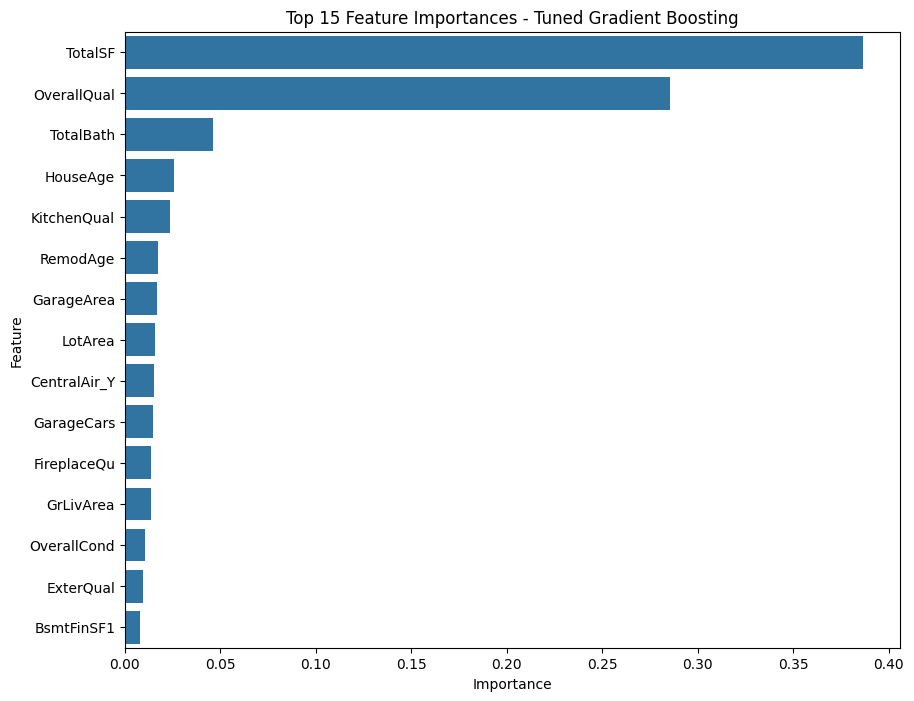

In [41]:
plt.figure(figsize=(10,8))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(15))
plt.title('Top 15 Feature Importances - Tuned Gradient Boosting')
plt.show()

## Model Comparison Report

Four regression algorithms were evaluated: Linear Regression, Random Forest, Ridge Regression, and Gradient Boosting. Gradient Boosting was additionally evaluated after hyperparameter tuning.

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 16070.70 | 23265.84 | 0.902 |
| Random Forest | 16382.14 | 23471.02 | 0.900 |
| Ridge Regression | 15675.83 | 22336.66 | 0.910 |
| Gradient Boosting | 14065.66 | 19811.00 | 0.929 |
| **Tuned Gradient Boosting** | **13585.01** | **18488.50** | **0.938** |

**Observations:**
- Random Forest performed slightly worse than plain Linear Regression, likely due to the high dimensionality (240 features after one-hot encoding) causing weaker splits without tuning.
- Ridge Regression improved over plain Linear Regression by penalizing large coefficients, helping with the multicollinearity among features like GarageCars/GarageArea and TotalBsmtSF/1stFlrSF.
- Gradient Boosting outperformed all baseline models by sequentially correcting prediction errors, capturing non-linear feature interactions.
- **Tuned Gradient Boosting achieved the best performance** after GridSearchCV hyperparameter tuning (learning_rate=0.05, max_depth=3, n_estimators=500, subsample=0.8), with the lowest RMSE (18488.50) and highest R² (0.938).


## Challenges Faced Report

**1. High Missing Values in Feature-Absence Columns**
Columns like PoolQC, Alley, Fence, MiscFeature, and FireplaceQu had very high missing percentages (up to 99%). However, per the data dictionary, NA in these columns means the feature is simply absent (e.g. no pool), not that data is truly missing.
*Technique used:* These were filled with 'None' instead of dropping, preserving valuable information (e.g. "no pool" is different from "unknown pool quality").

**2. Right-Skewed Target Variable (SalePrice)**
SalePrice showed a skewness of ~1.88, violating the linear regression assumption of normally distributed residuals and giving disproportionate influence to a few very expensive homes.
*Technique used:* Applied a log1p transformation to SalePrice before training, then inverse-transformed (expm1) predictions back to the original dollar scale for interpretable metrics.

**3. Outliers in Living Area vs Price**
Two houses had unusually large GrLivArea (>4000 sqft) but sold for less than $300,000 — a known anomaly in the Ames dataset, contradicting the otherwise strong positive relationship between size and price.
*Technique used:* These two rows were removed before training, as recommended by the dataset's original author, to prevent them from distorting the regression line.

**4. Multicollinearity Among Related Features**
GarageCars and GarageArea, as well as TotalBsmtSF and 1stFlrSF, were highly correlated with each other, which can inflate coefficient variance in linear models.
*Technique used:* Ridge Regression's L2 penalty was used to control this for linear models; tree-based models (Random Forest, Gradient Boosting) were largely unaffected since they select one of the correlated features per split.

**5. High Dimensionality After One-Hot Encoding**
One-hot encoding 43 categorical columns expanded the feature space from 79 to 240 columns, increasing the risk of overfitting, especially for Random Forest with default parameters.
*Technique used:* Gradient Boosting with hyperparameter tuning (shallow max_depth=3, subsample=0.8) was used to control overfitting through regularization rather than reducing dimensionality manually.

**6. GridSearchCV Tuning Overhead**
With 240 features and a moderately sized parameter grid (54 combinations × 5-fold CV = 270 model fits), hyperparameter tuning was computationally expensive.
*Technique used:* A focused grid (informed by domain knowledge of typical GBM ranges) and `n_jobs=-1` for parallel processing were used to keep tuning time manageable.

### Buyer Suggestions (Task 3)

In [42]:
# Price per sqft by neighborhood (use original df before encoding, or merge back)
neighborhood_stats = df_original.groupby('Neighborhood').agg(
    Avg_Price=('SalePrice', 'mean'),
    Avg_Quality=('OverallQual', 'mean'),
    Avg_GrLivArea=('GrLivArea', 'mean')
).round(0)

neighborhood_stats['Price_per_SqFt'] = (neighborhood_stats['Avg_Price'] / neighborhood_stats['Avg_GrLivArea']).round(2)
neighborhood_stats.sort_values('Price_per_SqFt').head(10)

,Avg_Price,Avg_Quality,Avg_GrLivArea,Price_per_SqFt
Neighborhood,,,,
SWISU,142591.0,5.0,1801.0,79.17
OldTown,128225.0,5.0,1480.0,86.64
IDOTRR,100124.0,5.0,1142.0,87.67
BrDale,104494.0,6.0,1143.0,91.42
MeadowV,98576.0,4.0,1059.0,93.08
Edwards,128220.0,5.0,1340.0,95.69
Blueste,137500.0,6.0,1392.0,98.78
BrkSide,124834.0,5.0,1203.0,103.77
NWAmes,189050.0,6.0,1728.0,109.40


* Neighborhoods like MeadowV, IDOTRR, and BrDale offer the lowest price-per-square-foot, making them good budget-friendly options for larger living space.
* Neighborhoods like NoRidge, NridgHt, and StoneBr have the highest average price and quality — best suited for buyers prioritizing premium finish and location over budget.
* For buyers balancing quality and cost, mid-range neighborhoods with above-average OverallQual but moderate price-per-sqft (e.g. Somerst, Timber) offer good value.
* Buyers focused on balancing space, quality, and price should pay particular attention to TotalSF and OverallQual, which together account for approximately 67% of the tuned Gradient Boosting model's feature importance.

## Conclusion

This project analyzed the Ames Housing dataset to predict house sale prices using 79+ explanatory features covering location, size, quality, and condition. After thorough data cleaning, EDA, feature engineering, and outlier removal, four regression models were trained and compared.

**Final Model: Tuned Gradient Boosting Regressor**
- MAE: $13,585.01
- RMSE: $18,488.50
- R² Score: 0.938 (highest among all models)

TotalSF and OverallQual emerged as the two most influential features in the tuned Gradient Boosting model, together accounting for approximately 67% of feature importance , followed by TotalBath, HouseAge, and KitchenQual. The tuned Gradient Boosting model is saved as `house_price_model.pkl` and is recommended for production deployment to predict house prices and guide buyer decisions based on area, quality, and budget.